# EDA básico: Statlog (German Credit Data)

Actividad Individual 2 · Análisis de Datos (FIUBA-CEIA, 5B2026)

Fuente: UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

1.000 solicitudes de crédito, 20 atributos (7 numéricos, 13 categóricos) y una clase: buen o mal crédito.

## 1. Carga de datos

El archivo `german.data` no trae encabezados y las columnas están separadas por espacios.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency, pointbiserialr

# Estilo de los gráficos (para todo el notebook)
sns.set_theme(style="whitegrid")

# sep=" ": las columnas están separadas por espacios
# header=None: el archivo no tiene fila de títulos
df = pd.read_csv("datos_raw/german.data", sep=" ", header=None)

In [15]:
# Dimensiones del dataset: (filas, columnas)
df.shape

(1000, 21)

**Interpretación:** 1.000 filas (una por solicitud de crédito) y 21 columnas: los 20 atributos más la clase.

In [16]:
# Primeras 5 filas
df.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


**Interpretación:** las columnas se llaman 0, 1, 2… porque el archivo no trae nombres, y varias contienen códigos (`A11`, `A34`…) en vez de texto. Los nombres se pueden tomar de la info de los atributos del document `german.doc`, en el mismo orden que el archivo. La última columna (`clase`) es la etiqueta: 1 = buen crédito, 2 = mal crédito.

In [17]:
# Asignamos los nombres a las 21 columnas (el orden es el del archivo german.doc)
df.columns = [
    "estado_cuenta",
    "duracion_meses",
    "historial_credito",
    "proposito",
    "monto_credito",
    "ahorros",
    "antiguedad_empleo",
    "cuota_pct_ingreso",
    "estado_civil_sexo",
    "otros_deudores",
    "anios_residencia",
    "propiedad",
    "edad",
    "otros_planes_cuotas",
    "vivienda",
    "creditos_en_banco",
    "trabajo",
    "personas_a_cargo",
    "telefono",
    "trabajador_extranjero",
    "clase",
]

df.head()

,estado_cuenta,duracion_meses,historial_credito,proposito,monto_credito,ahorros,antiguedad_empleo,cuota_pct_ingreso,estado_civil_sexo,otros_deudores,...,propiedad,edad,otros_planes_cuotas,vivienda,creditos_en_banco,trabajo,personas_a_cargo,telefono,trabajador_extranjero,clase
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


## 2. Estructura y tipos de variables

In [18]:
# Información general: tipo de dato y cantidad de valores no nulos de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   estado_cuenta          1000 non-null   str  
 1   duracion_meses         1000 non-null   int64
 2   historial_credito      1000 non-null   str  
 3   proposito              1000 non-null   str  
 4   monto_credito          1000 non-null   int64
 5   ahorros                1000 non-null   str  
 6   antiguedad_empleo      1000 non-null   str  
 7   cuota_pct_ingreso      1000 non-null   int64
 8   estado_civil_sexo      1000 non-null   str  
 9   otros_deudores         1000 non-null   str  
 10  anios_residencia       1000 non-null   int64
 11  propiedad              1000 non-null   str  
 12  edad                   1000 non-null   int64
 13  otros_planes_cuotas    1000 non-null   str  
 14  vivienda               1000 non-null   str  
 15  creditos_en_banco      1000 non-null   int64
 16  

**Interpretación:** hay 8 columnas numéricas (`int64`) y 13 de texto. Coincide con el documento del dataset, que habla de 7 atributos numéricos más la `clase`, que viene codificada como 1 y 2. Todas las columnas tienen 1000 valores no nulos. Los 13 atributos de texto son códigos (por ejemplo `A11`, `A12`) que representan categorías.

In [19]:
# Cantidad de valores distintos por columna.
df.nunique()

estado_cuenta              4
duracion_meses            33
historial_credito          5
proposito                 10
monto_credito            921
ahorros                    5
antiguedad_empleo          5
cuota_pct_ingreso          4
estado_civil_sexo          4
otros_deudores             3
anios_residencia           4
propiedad                  4
edad                      53
otros_planes_cuotas        3
vivienda                   3
creditos_en_banco          4
trabajo                    4
personas_a_cargo           2
telefono                   2
trabajador_extranjero      2
clase                      2
dtype: int64

**Interpretación:** `monto_credito` (921), `edad` (53) y `duracion_meses` (33) tienen muchos valores distintos. En cambio `cuota_pct_ingreso`, `anios_residencia` y `creditos_en_banco` tienen solo 4, y `personas_a_cargo` y `clase` solo 2.

### Clasificación de variables

**Cuantitativas continuas:** monto_credito, duracion_meses, edad

**Cuantitativas discretas:** cuota_pct_ingreso, anios_residencia, creditos_en_banco, personas_a_cargo

**Categóricas:** estado_cuenta, historial_credito, proposito, ahorros, antiguedad_empleo, estado_civil_sexo, otros_deudores, propiedad, otros_planes_cuotas, vivienda, trabajo, telefono, trabajador_extranjero, y clase (binaria: 1 buen crédito, 2 mal crédito)


**Criterios de la clasificación**

- Que una columna venga como número no la hace cuantitativa: `clase` es 1 o 2, pero son etiquetas (no tiene sentido promediarlas).
- Que una variable aparezca con pocos valores no la hace categórica: `personas_a_cargo` cuenta personas, así que es discreta aunque en esta muestra solo aparezcan 1 y 2.
- `clase` es binaria **por diseño**: el documento la define como buen o mal crédito (1 = Good, 2 = Bad) y trae una matriz de costos de 2×2.
- Las variables con pocos valores (4) se pueden tratar casi como categorías ordenadas.

### Recodificación de `clase`

Reemplazamos 1 y 2 por etiquetas legibles. Así los gráficos se entienden solos y `describe()` no mezcla la clase con las variables numéricas.

In [20]:
# map reemplaza cada valor según el diccionario (1 -> "bueno", 2 -> "malo")
df["clase"] = df["clase"].map({1: "bueno", 2: "malo"})

In [21]:
# Cuántas solicitudes hay de cada clase
df["clase"].value_counts()

clase
bueno    700
malo     300
Name: count, dtype: int64

**Interpretación:** 700 solicitudes con buen crédito (70 %) y 300 con mal crédito (30 %): hay más del doble de créditos buenos que malos.

### Ajuste de tipos

Pandas no asigna siempre el tipo correcto al importar (clase 2). Las 13 variables categóricas y la `clase` están como texto: las pasamos a tipo `category`.

In [22]:
# Todas las columnas que no son numéricas pasan a tipo category
categoricas = df.select_dtypes(exclude="number").columns
df[categoricas] = df[categoricas].astype("category")

df.dtypes

estado_cuenta            category
duracion_meses              int64
historial_credito        category
proposito                category
monto_credito               int64
ahorros                  category
antiguedad_empleo        category
cuota_pct_ingreso           int64
estado_civil_sexo        category
otros_deudores           category
anios_residencia            int64
propiedad                category
edad                        int64
otros_planes_cuotas      category
vivienda                 category
creditos_en_banco           int64
trabajo                  category
personas_a_cargo            int64
telefono                 category
trabajador_extranjero    category
clase                    category
dtype: object

## 3. Estadísticos descriptivos y faltantes

In [23]:
# Resumen estadístico de las columnas numéricas (count, mean, std, min, cuartiles, max)
df.describe()

,duracion_meses,monto_credito,cuota_pct_ingreso,anios_residencia,edad,creditos_en_banco,personas_a_cargo
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000


**Interpretación:**

- **`edad`:** promedio de 35,5 y mediana de 33. La diferencia es chica (unos 2 años), pero hay una cola hacia la derecha: la mayoría de los solicitantes es relativamente joven y algunas personas mayores suben un poco el promedio. La asimetría se mide más abajo.
- **`monto_credito`:** promedio de 3.271 y mediana de 2.319,5, con un máximo de 18.424. La **asimetría** es **mucho más marcada**: la mitad de los créditos está por debajo de 2.320 y unos pocos créditos muy grandes tiran el promedio hacia arriba. Para hablar del monto típico conviene la mediana, no el promedio.

In [24]:
# Asimetría (skewness) de las variables continuas: positiva = cola larga hacia la derecha
df[["duracion_meses", "monto_credito", "edad"]].skew().round(2)

duracion_meses    1.09
monto_credito     1.95
edad              1.02
dtype: float64

**Interpretación:** las tres variables tienen asimetría positiva, es decir, una cola hacia la derecha: la duración (1,09), el monto (1,95) y la edad (1,02). El monto es la más asimétrica de las tres, algo que ya se veía en el histograma y en la distancia entre promedio y mediana. Cuando hay asimetría el promedio deja de representar bien el centro, por eso para el monto conviene usar la mediana.

### Variables categóricas

In [25]:
# Resumen de las categóricas: cantidad, categorías distintas, categoría más frecuente y su frecuencia
df.describe(include="category").T

,count,unique,top,freq
estado_cuenta,1000,4,A14,394
historial_credito,1000,5,A32,530
proposito,1000,10,A43,280
ahorros,1000,5,A61,603
antiguedad_empleo,1000,5,A73,339
estado_civil_sexo,1000,4,A93,548
otros_deudores,1000,3,A101,907
propiedad,1000,4,A123,332
otros_planes_cuotas,1000,3,A143,814
vivienda,1000,3,A152,713


**Interpretación:** las 14 variables categóricas (incluida la clase) tienen las 1000 observaciones (no hay faltantes). Tienen entre 2 y 10 categorías; el propósito del crédito es la que más tiene (10). En varias domina una sola categoría: por ejemplo, en `otros_deudores` el 90,7 % cae en `A101` y en `trabajador_extranjero` el 96,3 % en `A201`. Esas variables aportan poca variación.

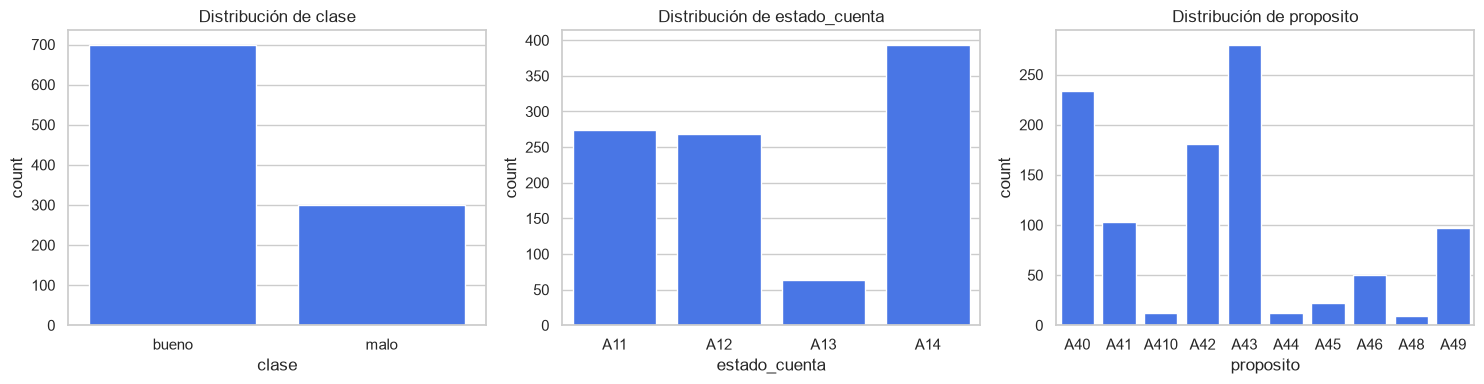

In [26]:
# Frecuencia de cada categoría en tres variables
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["clase", "estado_cuenta", "proposito"]):
    sns.countplot(x=col, data=df, color="#2F6BFF", ax=ax)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

**Interpretación:** la clase está repartida 700 / 300. En `estado_cuenta` la categoría más frecuente es `A14` (sin cuenta, 394 solicitudes). En `proposito` se concentra en `A43` (radio o televisión, 280), `A40` (auto nuevo, 234) y `A42` (muebles, 181), y las demás tienen bastante menos.

In [27]:
# Cantidad de valores vacíos por columna
print(df.isna().sum())

# Total de valores vacíos y mayor porcentaje en una columna
print("\nTotal de valores vacíos:", df.isna().sum().sum())
print("Mayor porcentaje de vacíos en una columna:", (df.isna().mean() * 100).max(), "%")

estado_cuenta            0
duracion_meses           0
historial_credito        0
proposito                0
monto_credito            0
ahorros                  0
antiguedad_empleo        0
cuota_pct_ingreso        0
estado_civil_sexo        0
otros_deudores           0
anios_residencia         0
propiedad                0
edad                     0
otros_planes_cuotas      0
vivienda                 0
creditos_en_banco        0
trabajo                  0
personas_a_cargo         0
telefono                 0
trabajador_extranjero    0
clase                    0
dtype: int64

Total de valores vacíos: 0
Mayor porcentaje de vacíos en una columna: 0.0 %


**Interpretación:** no hay valores faltantes en ninguna columna. Los valores de texto son códigos válidos del documento del dataset.

## 4. Gráficos y relaciones entre variables

Colores: azul para las solicitudes con buen crédito y rojo para las de mal crédito.

In [28]:
# Colores fijos para la clase, así se repiten en todos los gráficos
colores = {"bueno": "#2F6BFF", "malo": "#E5484D"}

### 4.1 Distribución del monto, la duración y la edad

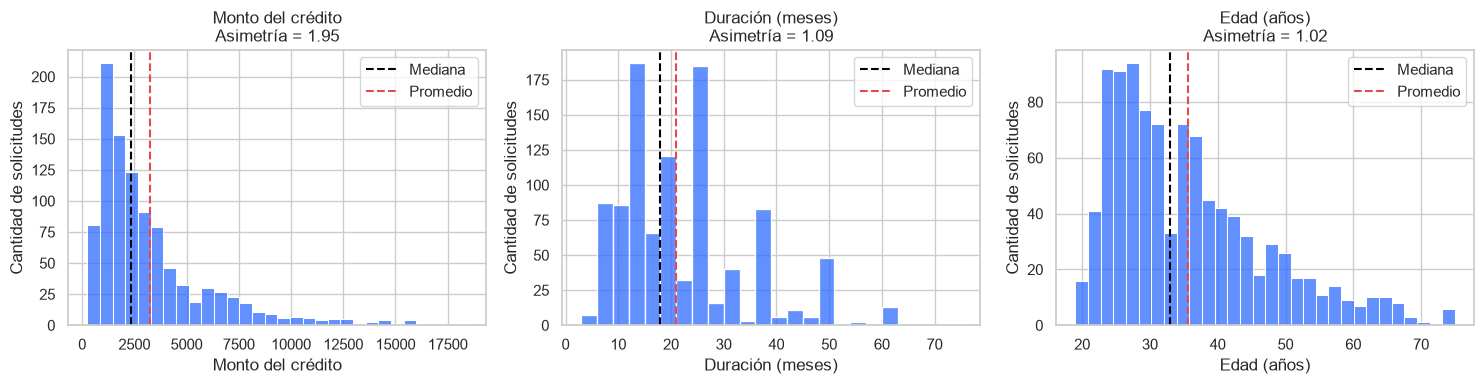

In [29]:
# Histogramas de las tres variables continuas, con líneas en la mediana y el promedio
# En el título de cada uno va la asimetría (skewness)
# bins: para la duración usamos intervalos de 3 meses, porque son meses enteros y 30 bins dejan huecos
variables = {
    "monto_credito": ("Monto del crédito", 30),
    "duracion_meses": ("Duración (meses)", np.arange(3, 76, 3)),
    "edad": ("Edad (años)", 30),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, (nombre, bins)) in zip(axes, variables.items()):
    sns.histplot(data=df, x=col, bins=bins, color="#2F6BFF", ax=ax)
    ax.axvline(df[col].median(), color="black", linestyle="--", label="Mediana")
    ax.axvline(df[col].mean(), color="#E5484D", linestyle="--", label="Promedio")
    ax.set_title(f"{nombre}\nAsimetría = {df[col].skew():.2f}")
    ax.set_xlabel(nombre)
    ax.set_ylabel("Cantidad de solicitudes")
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretación:** las tres variables tienen cola hacia la derecha, y en las tres el promedio (línea roja) queda a la derecha de la mediana (línea negra). **Ninguna de las tres es simétrica.** La asimetría es muy distinta entre ellas:

- **Monto (1,95):** es la más marcada de las tres. La mayoría de los créditos es chica y unos pocos son muy grandes (el máximo es 18.424, según el `describe()` de la sección 3).
- **Duración (1,09):** el 77 % de los créditos es de 24 meses o menos. Los plazos se concentran en valores redondos (24 meses es el más frecuente, con 184 solicitudes, y 12 meses le sigue con 179), y hay una cola con plazos largos de 36, 48 y 60 meses.
- **Edad (1,02):** la mayoría de los solicitantes tiene entre 20 y 40 años, y baja de a poco hacia las edades mayores. Es la menos extrema de las tres.

### 4.2 Monto del crédito según la clase

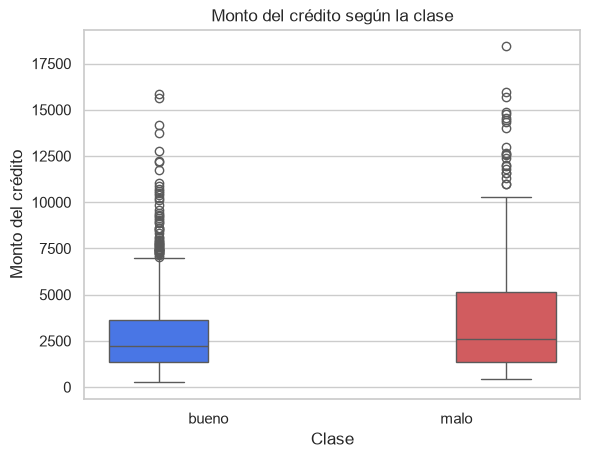

,count,mean,std,min,25%,50%,75%,max
clase,,,,,,,,
bueno,700.0,2985.0,2401.0,250.0,1376.0,2244.0,3635.0,15857.0
malo,300.0,3938.0,3536.0,433.0,1352.0,2574.0,5142.0,18424.0


In [30]:
# Boxplot del monto, separado por buen y mal crédito
sns.boxplot(data=df, x="clase", y="monto_credito", hue="clase", palette=colores, order=["bueno", "malo"], legend=False)
plt.title("Monto del crédito según la clase")
plt.xlabel("Clase")
plt.ylabel("Monto del crédito")
plt.show()

# Estadísticos del monto por clase (la fila 75% es el borde de arriba de la caja)
df.groupby("clase")["monto_credito"].describe().round(0)

**Interpretación:** en la tabla de arriba se ve que los créditos clasificados como malos tienden a ser más grandes:

- **Mediana (50 %):** 2.574 en los malos contra 2.244 en los buenos.
- **Promedio (`mean`):** 3.938 contra 2.985.
- **Fila 75 %:** es el valor por debajo del cual está el 75 % de los créditos de esa clase; en el boxplot es el borde de arriba de la caja. En los malos es 5.142 y en los buenos 3.635, o sea que 1 de cada 4 créditos malos supera los 5.142, mientras que entre los buenos solo 1 de cada 4 supera los 3.635.

Las dos cajas se superponen bastante, así que el monto por sí solo no separa bien las dos clases.

### 4.2 (bis) Monto del crédito según la clase: histograma superpuesto

El boxplot resume la distribución en pocos números. Para ver su forma completa, superponemos el histograma de cada clase. Como hay 700 buenos y 300 malos, cada clase se grafica como porcentaje de **su propio total**, así las dos curvas se pueden comparar.

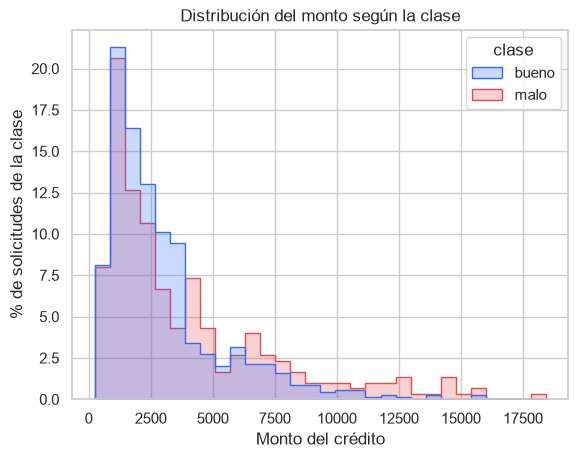

Superan 5000:
clase
bueno    15.7
malo     26.0
Name: monto_credito, dtype: float64
Superan 7500:
clase
bueno     6.0
malo     14.7
Name: monto_credito, dtype: float64


In [31]:
# Histograma superpuesto del monto, uno por clase
# stat="percent" + common_norm=False: cada clase suma 100 % por separado
sns.histplot(data=df, x="monto_credito", hue="clase", palette=colores, stat="percent", common_norm=False, element="step", bins=30)
plt.title("Distribución del monto según la clase")
plt.xlabel("Monto del crédito")
plt.ylabel("% de solicitudes de la clase")
plt.show()

# Porcentaje de créditos que superan 5.000 y 7.500, para cada clase
for umbral in [5000, 7500]:
    print(f"Superan {umbral}:")
    print(((df["monto_credito"] > umbral).groupby(df["clase"]).mean() * 100).round(1))

**Interpretación:** las dos clases tienen la misma forma general, con la mayoría de los créditos por debajo de 5.000, pero los créditos malos tienen una **cola derecha más pesada**: en los montos grandes la curva roja queda por encima de la azul. Los números lo confirman: el 26,0 % de los créditos malos supera los 5.000, contra el 15,7 % de los buenos, y el 14,7 % contra el 6,0 % si el umbral es 7.500. En cambio, en los montos chicos y medios (hasta unos 3.500) la curva azul queda un poco por encima: los buenos se concentran más ahí. Aun así las dos distribuciones se superponen mucho, que es lo que habíamos visto en el boxplot: el monto por sí solo no separa bien las clases, pero los créditos muy grandes son proporcionalmente más frecuentes entre los malos.

### 4.3 Duración y monto: relación entre dos variables numéricas

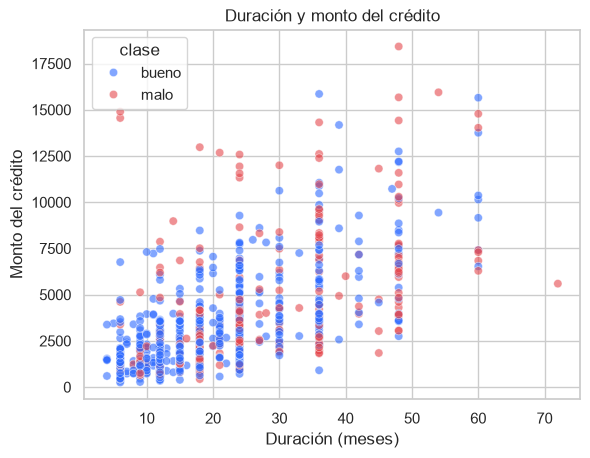

Correlación duración-monto: 0.62
clase
bueno    18.0
malo     24.0
Name: duracion_meses, dtype: float64


In [32]:
# Dispersión: cada punto es una solicitud, coloreada según su clase
sns.scatterplot(data=df, x="duracion_meses", y="monto_credito", hue="clase", palette=colores, alpha=0.6)
plt.title("Duración y monto del crédito")
plt.xlabel("Duración (meses)")
plt.ylabel("Monto del crédito")
plt.show()

# Correlación entre las dos variables (Pearson)
print("Correlación duración-monto:", round(df["duracion_meses"].corr(df["monto_credito"]), 2))

# Duración mediana (en meses) según la clase
print(df.groupby("clase")["duracion_meses"].median())

**Interpretación:** hay una relación positiva moderada: a mayor duración, mayor monto (correlación de 0,62). Posiblemente porque los créditos más grandes se pagan en más meses (es una explicación posible, no algo que muestren los datos). Los puntos rojos (mal crédito) se concentran un poco más arriba y a la derecha, es decir, en créditos largos y grandes. La duración mediana es de 24 meses en los créditos malos contra 18 en los buenos.

### 4.3 (bis) Matriz de correlación de las variables numéricas

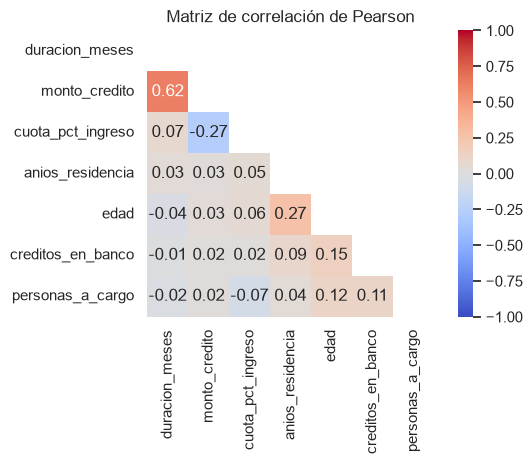

In [33]:
# Correlación de Pearson entre las 7 variables numéricas (mostramos solo la mitad de abajo)
numericas = ["duracion_meses", "monto_credito", "cuota_pct_ingreso", "anios_residencia", "edad", "creditos_en_banco", "personas_a_cargo"]
matriz = df[numericas].corr()
mascara = np.triu(np.ones_like(matriz, dtype=bool))

sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, mask=mascara)
plt.title("Matriz de correlación de Pearson")
plt.grid(False)
plt.tight_layout()
plt.show()

**Interpretación:** la única correlación alta es la de duración y monto (0,62). Aparecen dos más débiles: monto y cuota como porcentaje del ingreso (-0,27, a mayor monto, menor cuota relativa) y edad y años en la residencia actual (0,27). El resto está cerca de 0, es decir, casi no hay relación lineal entre esas variables.

### 4.4 Estado de la cuenta corriente y clase: relación entre dos variables categóricas

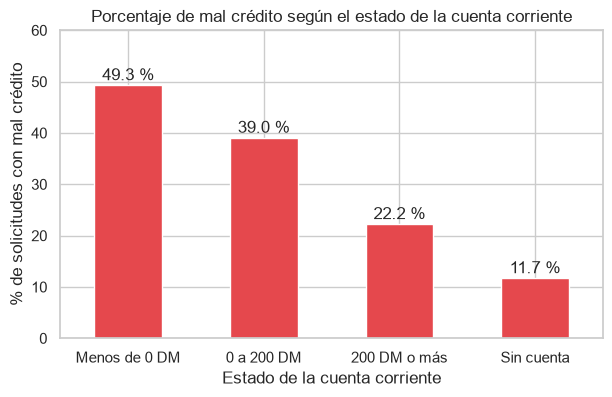

In [34]:
# Porcentaje de solicitudes con mal crédito en cada estado de cuenta
etiquetas = {"A11": "Menos de 0 DM", "A12": "0 a 200 DM", "A13": "200 DM o más", "A14": "Sin cuenta"}
pct_malo = pd.crosstab(df["estado_cuenta"], df["clase"], normalize="index")["malo"] * 100
pct_malo.index = pct_malo.index.map(etiquetas)

ax = pct_malo.plot(kind="bar", color="#E5484D", figsize=(7, 4))
for i, v in enumerate(pct_malo):
    ax.text(i, v + 1, f"{v:.1f} %", ha="center")
plt.title("Porcentaje de mal crédito según el estado de la cuenta corriente")
plt.xlabel("Estado de la cuenta corriente")
plt.ylabel("% de solicitudes con mal crédito")
plt.xticks(rotation=0)
plt.ylim(0, 60)
plt.show()

**Interpretación:** es la relación más fuerte de las que vi. Entre quienes tienen la cuenta en rojo (menos de 0 DM), casi la mitad (49,3 %) tiene mal crédito; entre quienes no tienen cuenta corriente, solo el 11,7 %. El porcentaje baja a medida que mejora el estado de la cuenta (49,3 %, 39,0 %, 22,2 % y 11,7 %). Es llamativo que la categoría con menor riesgo sea la de quienes directamente no tienen cuenta.

### 4.5 Medidas de asociación con la clase

- **Cramér's V** mide la fuerza de la asociación entre dos variables categóricas (se apoya en el test chi-cuadrado).
- **Correlación punto biserial** mide la asociación entre una variable numérica y una binaria. Para calcularla hay que representar la clase como 0 y 1.

In [35]:
# Cramér's V entre dos variables categóricas
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.sum().sum()
    filas, columnas = tabla.shape
    return np.sqrt(chi2 / (n * min(filas - 1, columnas - 1)))

# Test chi-cuadrado de independencia: estado de la cuenta contra clase
tabla = pd.crosstab(df["estado_cuenta"], df["clase"])
chi2, p, grados, esperadas = chi2_contingency(tabla)
print(f"chi-cuadrado = {chi2:.1f}, grados de libertad = {grados}, p-valor = {p:.1e}")
print("Frecuencia esperada mínima:", esperadas.min().round(1))
print("Cramér's V:", round(cramers_v(df["estado_cuenta"], df["clase"]), 2))

chi-cuadrado = 123.7, grados de libertad = 3, p-valor = 1.2e-26
Frecuencia esperada mínima: 18.9
Cramér's V: 0.35


**Interpretación:** el test chi-cuadrado da un p-valor muy chico (del orden de 1e-26), así que se rechaza la hipótesis de independencia: el estado de la cuenta y la clase están asociados. Además, la frecuencia esperada mínima es 18,9, que cumple la Regla de Cochran (las frecuencias esperadas no deben ser demasiado chicas). El chi-cuadrado solo dice *si* hay relación; Cramér's V dice *cuánta*: vale 0,35, una asociación **moderada**.

In [36]:
# Cramér's V de cada variable categórica contra la clase
categoricas = df.select_dtypes(exclude="number").columns.drop("clase")
v_clase = pd.Series({col: cramers_v(df[col], df["clase"]) for col in categoricas})
v_clase.sort_values(ascending=False).round(2)

estado_cuenta            0.35
historial_credito        0.25
ahorros                  0.19
proposito                0.18
propiedad                0.15
antiguedad_empleo        0.14
vivienda                 0.13
otros_planes_cuotas      0.11
estado_civil_sexo        0.10
otros_deudores           0.08
trabajador_extranjero    0.08
trabajo                  0.04
telefono                 0.03
dtype: float64

**Interpretación:** entre las 13 variables categóricas, `estado_cuenta` tiene el mayor Cramér's V con la clase (0,35). Le siguen `historial_credito` (0,25), `ahorros` (0,19) y `proposito` (0,18). `trabajo` y `telefono` casi no tienen relación (0,04 y 0,03). Esto indica que, según Cramér's V, el estado de la cuenta es la variable categórica que más se asocia con la clase.

In [37]:
# Correlación punto biserial entre cada variable numérica y la clase (1 = mal crédito, 0 = buen crédito)
clase_01 = (df["clase"] == "malo").astype(int)

filas = []
for col in ["duracion_meses", "monto_credito", "edad"]:
    r, p = pointbiserialr(clase_01, df[col])
    filas.append((col, round(r, 2), f"{p:.1e}"))
pd.DataFrame(filas, columns=["variable", "correlación", "p-valor"])

,variable,correlación,p-valor
0,duracion_meses,0.21,6.5e-12
1,monto_credito,0.15,8.8e-07
2,edad,-0.09,3.9e-03


**Interpretación:** las tres asociaciones con la clase son **débiles**: la duración (0,21) es la más fuerte, después el monto (0,15), y la edad tiene una relación negativa muy chica (-0,09): a mayor edad, algo menos de mal crédito. Los p-valores son chicos, así que las relaciones no son casuales, pero la magnitud es baja. Es el mismo caso que vimos en la clase: una relación puede ser estadísticamente significativa y aun así débil. Esto coincide con el boxplot, donde las cajas de buenos y malos se superponían mucho.

## 5. Conclusiones

- El dataset tiene 1.000 solicitudes de crédito y 21 columnas (20 atributos y la clase), está **completo** (sin valores faltantes) y mezcla variables numéricas y categóricas codificadas.
- La clase está repartida 70 % buen crédito y 30 % mal crédito.
- El monto del crédito tiene una asimetría fuerte a la derecha: la mediana (2.319,5) representa mejor el caso típico que el promedio (3.271).
- Los créditos malos tienden a ser más grandes y más largos que los buenos (según las medianas), pero los rangos se superponen mucho, por lo que ni el monto ni la duración alcanzan por sí solos para separarlos.
- Entre las numéricas, la única correlación alta es la de duración y monto (0,62); el resto es débil o casi nula.
- Las categóricas tienen entre 2 y 10 categorías y en varias domina una sola (por ejemplo, el 96,3 % de `trabajador_extranjero`).
- Las tres variables numéricas continuas se asocian débilmente con la clase (punto biserial: 0,21 la duración, 0,15 el monto, -0,09 la edad).
- Entre las 13 variables categóricas, el estado de la cuenta corriente es la más asociada con la clase según Cramér's V (0,35, asociación moderada): el porcentaje de mal crédito va de 49,3 % (cuenta en rojo) a 11,7 % (sin cuenta).